<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/standard_model/sm_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Standard Model* — `sm_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Standard Model Ch 2 Figures — Colab Notebook
**The Standard Model · Chapter 2: Broken Symmetries**

Tong (DAMTP, Cambridge) · Run each cell to generate figures.
Output: `figures/ch02/fig0N_*.png`

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §2.1    | $\mathbb{Z}_2$ double-well potential and domain wall profile |
| fig02  | §2.3    | Higgs mechanism: Goldstone eaten, gauge boson mass generation |
| fig03  | §2.4    | Vortex field profiles $|\phi(r)|$, $B(r)$; Type I vs II phase diagram |

## Setup — dark palette & output directory

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Arc, Wedge
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import os

# ── Dark palette (Standard Model series — teal/cyan accent) ───────────────
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
TEAL   = '#2ec4b6'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#e8a838'

plt.rcParams.update({
    'figure.facecolor'   : BG,
    'axes.facecolor'     : BG,
    'text.color'         : FG,
    'axes.labelcolor'    : FG,
    'xtick.color'        : FG,
    'ytick.color'        : FG,
    'axes.edgecolor'     : EDGE,
    'grid.color'         : EDGE,
    'grid.alpha'         : 0.3,
    'font.size'          : 12,
    'axes.titlesize'     : 13,
    'axes.titleweight'   : 'bold',
    'axes.titlecolor'    : TEAL,
    'legend.framealpha'  : 0.3,
    'legend.edgecolor'   : EDGE,
    'xtick.major.size'   : 4,
    'ytick.major.size'   : 4,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.linewidth'     : 1.2,
    'lines.linewidth'    : 2.2,
    'figure.dpi'         : 110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete. Palette and output directory ready.')

Setup complete. Palette and output directory ready.


---
## fig01 · $\mathbb{Z}_2$ Potential and Domain Wall (§2.1)

**Left**: Double-well potential $V(\phi) = -\frac{\mu^2}{2}\phi^2 + \frac{\lambda}{4}\phi^4$,
showing two degenerate minima at $\phi = \pm v$  
**Middle**: Domain wall profile $\phi(x) = v\tanh(x/\sqrt{2}\,\xi)$ interpolating between vacua  
**Right**: Energy density $\mathcal{E}(x)$ of the domain wall — localised near $x=0$

  saved -> figures/ch02/fig01_potential_dw.png


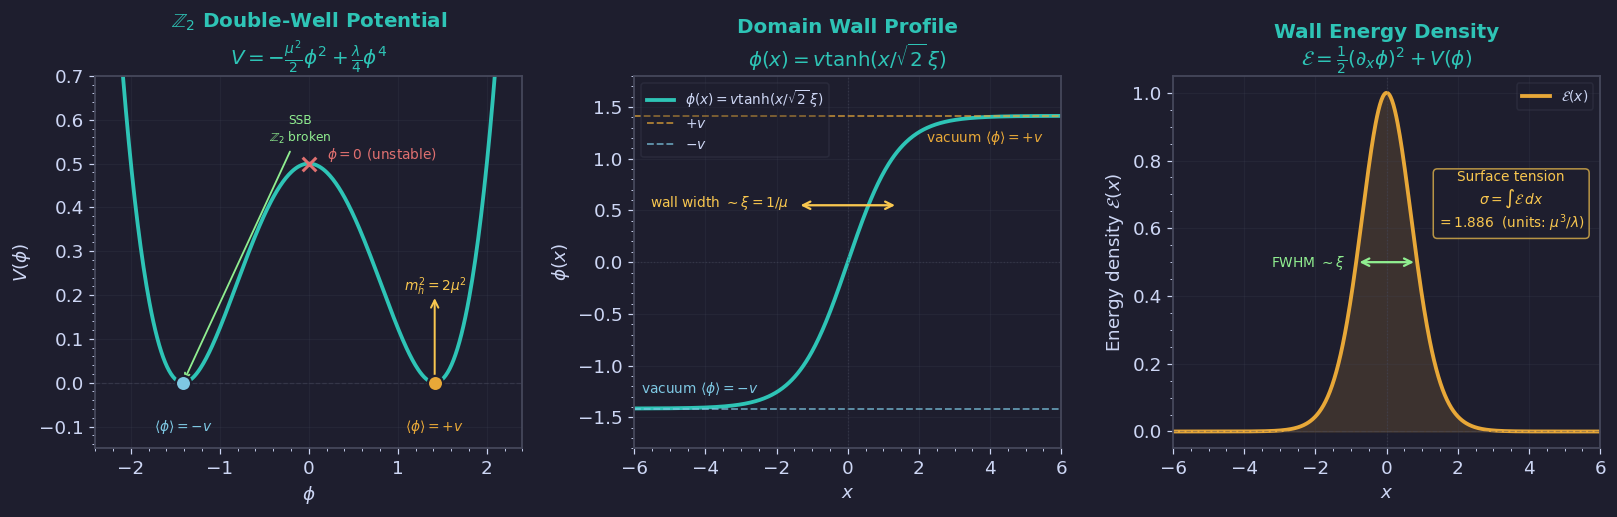

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

mu2 = 1.0
lam = 0.5
v   = np.sqrt(mu2 / lam)           # = sqrt(2)
xi  = 1.0 / np.sqrt(mu2)           # correlation length

# ── Left: double-well potential ───────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

phi = np.linspace(-2.2, 2.2, 400)
V   = -0.5 * mu2 * phi**2 + 0.25 * lam * phi**4
# Shift so minima are at V=0
V  -= V.min()

ax.plot(phi, V, color=TEAL, lw=2.5)

# Mark minima
for sign, col, lbl in [(-1, BLUE, r'$\langle\phi\rangle = -v$'),
                        (+1, ORANGE, r'$\langle\phi\rangle = +v$')]:
    xm = sign * v
    ax.scatter([xm], [0], s=100, color=col, zorder=5, edgecolors=BG, lw=1.5)
    ax.text(xm, -0.08, lbl, ha='center', va='top', color=col, fontsize=9)

# Mark local maximum (false vacuum)
ax.scatter([0], [mu2**2 / (4*lam)], s=80, color=RED, marker='x',
           zorder=5, linewidths=2)
ax.text(0.2, mu2**2/(4*lam) + 0.01, r'$\phi=0$ (unstable)', color=RED, fontsize=9)

# Curvature annotation at minima
ax.annotate('', xy=(v, 0.2), xytext=(v, 0.0),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.3))
ax.text(v -0.34, 0.21, r'$m_h^2 = 2\mu^2$', color=YELLOW, fontsize=9)

# Symmetry breaking arrow
ax.annotate('SSB\n$\\mathbb{Z}_2$ broken', xy=(-v, 0.0), xytext=(-0.1, 0.55),
            ha='center', color=GREEN, fontsize=8,
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.2))

ax.set_xlabel(r'$\phi$')
ax.set_ylabel(r'$V(\phi)$')
ax.set_title(r'$\mathbb{Z}_2$ Double-Well Potential' + '\n'
             + r'$V = -\frac{\mu^2}{2}\phi^2 + \frac{\lambda}{4}\phi^4$',
             color=TEAL)
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-0.15, 0.7)
ax.axhline(0, color=EDGE, lw=0.8, ls='--', alpha=0.5)
ax.grid(True, alpha=0.2)

# ── Middle: domain wall profile ───────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

x    = np.linspace(-6, 6, 600)
phi_dw = v * np.tanh(x / (np.sqrt(2) * xi))

ax2.plot(x, phi_dw, color=TEAL, lw=2.5, label=r'$\phi(x)=v\tanh(x/\sqrt{2}\,\xi)$')
ax2.axhline(+v,  color=ORANGE, lw=1.2, ls='--', alpha=0.7, label=r'$+v$')
ax2.axhline(-v,  color=BLUE,   lw=1.2, ls='--', alpha=0.7, label=r'$-v$')
ax2.axhline(0,   color=EDGE,   lw=0.8, ls=':',  alpha=0.5)
ax2.axvline(0,   color=EDGE,   lw=0.8, ls=':',  alpha=0.5)

# Wall width annotation
ax2.annotate('', xy=(np.sqrt(2)*xi, 0.55), xytext=(-np.sqrt(2)*xi, 0.55),
             arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.5))
ax2.text(-3.6, 0.53, r'wall width $\sim \xi = 1/\mu$',
         ha='center', color=YELLOW, fontsize=9)

# Vacuum labels
ax2.text(-5.8, -v + 0.15, r'vacuum $\langle\phi\rangle = -v$', color=BLUE, fontsize=9)
ax2.text(+2.2, +v - 0.25, r'vacuum $\langle\phi\rangle = +v$', color=ORANGE, fontsize=9)

ax2.set_xlabel(r'$x$')
ax2.set_ylabel(r'$\phi(x)$')
ax2.set_title('Domain Wall Profile\n' + r'$\phi(x) = v\tanh(x/\sqrt{2}\,\xi)$',
              color=TEAL)
ax2.set_xlim(-6, 6)
ax2.set_ylim(-1.8, 1.8)
ax2.legend(fontsize=9, loc='upper left', labelcolor=FG)
ax2.grid(True, alpha=0.2)

# ── Right: energy density ─────────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# Energy density: E = (1/2)(d phi/dx)^2 + V(phi)
dphi_dx = np.gradient(phi_dw, x)
V_phi   = -0.5*mu2*phi_dw**2 + 0.25*lam*phi_dw**4
V_phi  -= V_phi.min()
E_dens  = 0.5 * dphi_dx**2 + V_phi

ax3.plot(x, E_dens, color=ORANGE, lw=2.5, label=r'$\mathcal{E}(x)$')
ax3.fill_between(x, 0, E_dens, alpha=0.15, color=ORANGE)

# Total surface tension (area under curve)
sigma = np.trapezoid(E_dens, x)
ax3.text(3.5, E_dens.max() * 0.6,
         f'Surface tension\n' + r'$\sigma = \int\mathcal{E}\,dx$' + '\n' +rf'$= {sigma:.3f}$  (units: $\mu^3/\lambda$)',
         ha='center', color=YELLOW, fontsize=9,
         bbox=dict(boxstyle='round', fc=BG, ec=YELLOW, alpha=0.7))

ax3.axvline(0, color=EDGE, lw=0.8, ls=':', alpha=0.5)
ax3.axhline(0, color=EDGE, lw=0.8, ls='--', alpha=0.4)

# FWHM width
half_max = E_dens.max() / 2
idx_half = np.where(E_dens >= half_max)[0]
if len(idx_half) > 1:
    x_l, x_r = x[idx_half[0]], x[idx_half[-1]]
    ax3.annotate('', xy=(x_r, half_max), xytext=(x_l, half_max),
                 arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5))
    ax3.text(-2.2, half_max -0.03, r'FWHM $\sim \xi$',
             ha='center', va='bottom', color=GREEN, fontsize=9)

ax3.set_xlabel(r'$x$')
ax3.set_ylabel(r'Energy density $\mathcal{E}(x)$')
ax3.set_title('Wall Energy Density\n' +
              r'$\mathcal{E} = \frac{1}{2}(\partial_x\phi)^2 + V(\phi)$', color=TEAL)
ax3.set_xlim(-6, 6)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.2)

plt.tight_layout(pad=1.5)
save('fig01_potential_dw.png', fig)

---
## fig02 · Higgs Mechanism (§2.3)

**Left**: Mexican hat potential $V(|\phi|)$ in 2D field space — circle of minima at $|\phi|=v$  
**Middle**: Degree-of-freedom counting before and after SSB — Goldstone eaten by gauge boson  
**Right**: Gauge boson mass $m_A = ev$ as a function of $v$ for several values of $e$

  saved -> figures/ch02/fig02_higgs_mechanism.png


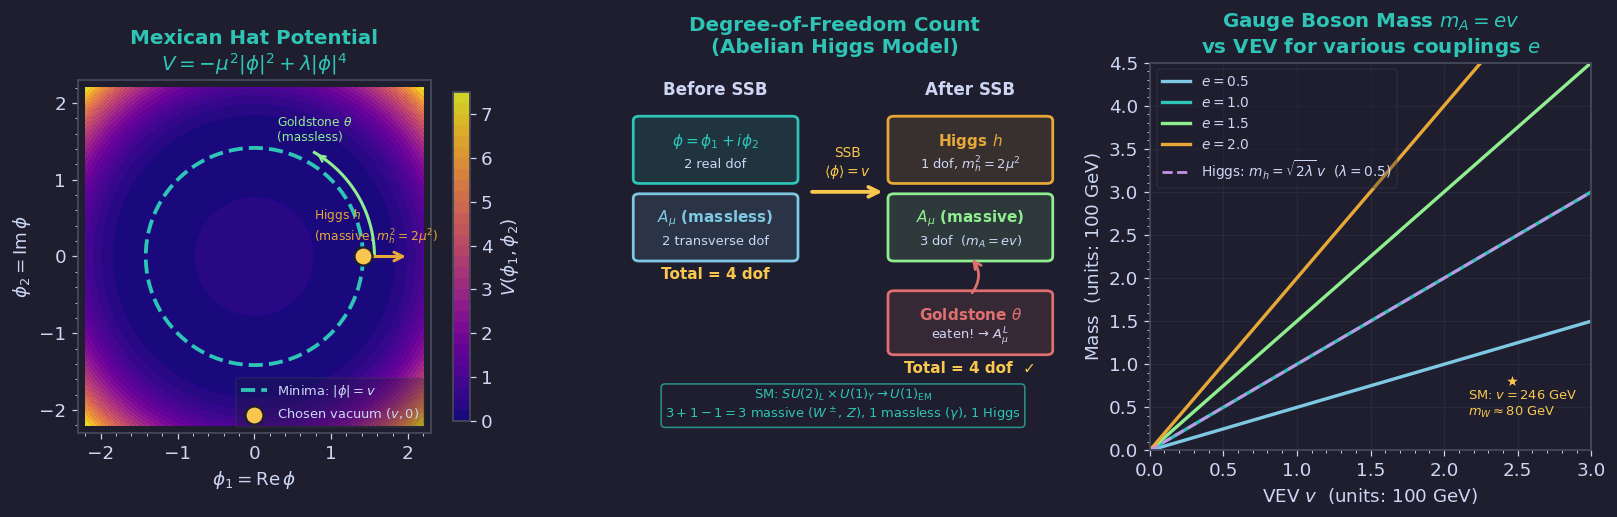

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

mu2 = 1.0
lam = 0.5
v   = np.sqrt(mu2 / lam)

# ── Left: Mexican hat potential ───────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

phi1 = np.linspace(-2.2, 2.2, 300)
phi2 = np.linspace(-2.2, 2.2, 300)
P1, P2 = np.meshgrid(phi1, phi2)
R2 = P1**2 + P2**2
V_hat = -0.5*mu2*R2 + 0.25*lam*R2**2
V_hat -= V_hat.min()

cf = ax.contourf(P1, P2, V_hat, levels=30, cmap='plasma', alpha=0.85)
plt.colorbar(cf, ax=ax, label=r'$V(\phi_1, \phi_2)$', shrink=0.85)

# Circle of minima
theta_circ = np.linspace(0, 2*np.pi, 200)
ax.plot(v*np.cos(theta_circ), v*np.sin(theta_circ),
        color=TEAL, lw=2.5, ls='--', label=r'Minima: $|\phi|=v$')

# Chosen vacuum
ax.scatter([v], [0], s=140, color=YELLOW, zorder=6,
           edgecolors=BG, lw=1.5, label=r'Chosen vacuum $(v,0)$')

# Radial direction (Higgs) and angular direction (Goldstone)
ax.annotate('', xy=(v + 0.6, 0.0), xytext=(v + 0.05, 0.0),
            arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.0, mutation_scale=14))
ax.text(v - 0.64, 0.2, r'Higgs $h$'+"\n"+r'(massive, $m_h^2=2\mu^2$)',
        color=ORANGE, fontsize=8)

# Angular arc
theta_arc = np.linspace(0, np.pi/3, 50)
ax.plot((v+0.15)*np.cos(theta_arc), (v+0.15)*np.sin(theta_arc),
        color=GREEN, lw=2.0)
ax.annotate('', xy=((v+0.15)*np.cos(np.pi/3), (v+0.15)*np.sin(np.pi/3)),
            xytext=((v+0.15)*np.cos(np.pi/3 - 0.15), (v+0.15)*np.sin(np.pi/3 - 0.15)),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.5, mutation_scale=10))
ax.text(0.3, 1.5, r'Goldstone $\theta$'+"\n"+'(massless)', color=GREEN, fontsize=8)

ax.set_xlabel(r'$\phi_1 = \mathrm{Re}\,\phi$')
ax.set_ylabel(r'$\phi_2 = \mathrm{Im}\,\phi$')
ax.set_title('Mexican Hat Potential\n' +
             r'$V = -\mu^2|\phi|^2 + \lambda|\phi|^4$', color=TEAL)
ax.set_xlim(-2.3, 2.3)
ax.set_ylim(-2.3, 2.3)
ax.set_aspect('equal')
ax.legend(fontsize=8.5, loc='lower right', labelcolor=FG)

# ── Middle: DoF counting diagram ──────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(-0.2, 5.0)
ax2.set_ylim(-0.5, 5.5)
ax2.axis('off')
ax2.set_title('Degree-of-Freedom Count\n(Abelian Higgs Model)', color=TEAL)

def dof_box(ax, x, y, w, h, label, sublabel, col):
    rect = FancyBboxPatch((x, y), w, h,
                          boxstyle='round,pad=0.07',
                          linewidth=1.8, edgecolor=col,
                          facecolor=col + '22')
    ax.add_patch(rect)
    ax.text(x + w/2, y + h*0.65, label,
            ha='center', va='center', color=col,
            fontsize=10, fontweight='bold')
    ax.text(x + w/2, y + h*0.25, sublabel,
            ha='center', va='center', color=FG, fontsize=8.5)

# BEFORE SSB column
ax2.text(1.0, 5.0, 'Before SSB', ha='center', color=FG, fontsize=11, fontweight='bold')
dof_box(ax2, 0.1, 3.7, 1.8, 0.9, r'$\phi = \phi_1 + i\phi_2$', '2 real dof', TEAL)
dof_box(ax2, 0.1, 2.5, 1.8, 0.9, r'$A_\mu$ (massless)', '2 transverse dof', BLUE)
ax2.text(1.0, 2.15, 'Total = 4 dof', ha='center', color=YELLOW, fontsize=10,
         fontweight='bold')

# Arrow pointing right
ax2.annotate('', xy=(3.0, 3.5), xytext=(2.1, 3.5),
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.5, mutation_scale=16))
ax2.text(2.55, 3.75, 'SSB\n$\\langle\\phi\\rangle=v$', ha='center', color=YELLOW, fontsize=9)

# AFTER SSB column
ax2.text(4.0, 5.0, 'After SSB', ha='center', color=FG, fontsize=11, fontweight='bold')
dof_box(ax2, 3.1, 3.7, 1.8, 0.9, r'Higgs $h$', r'1 dof, $m_h^2 = 2\mu^2$', ORANGE)
dof_box(ax2, 3.1, 2.5, 1.8, 0.9, r'$A_\mu$ (massive)', r'3 dof  ($m_A = ev$)', GREEN)
dof_box(ax2, 3.1, 1.05, 1.8, 0.85, r'Goldstone $\theta$', r'eaten! → $A_\mu^L$', RED)
ax2.text(4.0, 0.7, 'Total = 4 dof  ✓', ha='center', color=YELLOW, fontsize=10,
         fontweight='bold')

# Curved arrow from Goldstone to massive gauge
ax2.annotate('', xy=(4.0, 2.5), xytext=(4.0, 1.9),
             arrowprops=dict(arrowstyle='->', color=RED, lw=1.8,
                             connectionstyle='arc3,rad=0.4'))

# SM numbers
ax2.text(2.5, 0.0,
         'SM: $SU(2)_L\\times U(1)_Y \\to U(1)_{\\rm EM}$\n'
         '$3+1-1 = 3$ massive ($W^\\pm$, $Z$), 1 massless ($\\gamma$), 1 Higgs',
         ha='center', color=TEAL, fontsize=8.5,
         bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.7))

# ── Right: mass vs VEV ────────────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

v_range = np.linspace(0, 3.0, 300)
e_vals  = [0.5, 1.0, 1.5, 2.0]
colours_e = [BLUE, TEAL, GREEN, ORANGE]

for e, col in zip(e_vals, colours_e):
    mA = e * v_range
    ax3.plot(v_range, mA, color=col, lw=2.2, label=f'$e = {e}$')

# SM point: v=246 GeV, mW=80.4 GeV  (normalised)
v_SM  = 246 / 100   # scaled for plot
mW_SM = 80.4 / 100
ax3.scatter([v_SM], [mW_SM], s=150, color=YELLOW, zorder=6,
            edgecolors=BG, lw=1.5, marker='*')
ax3.text(v_SM -0.3, mW_SM - 0.4,
         r'SM: $v=246$ GeV' + '\n' + r'$m_W\approx80$ GeV',
         color=YELLOW, fontsize=8.5)

# Higgs mass line (independent of e)
mh_range = np.sqrt(2 * lam) * v_range   # lam=0.5 -> mh = v (roughly)
ax3.plot(v_range, mh_range, color=PURPLE, lw=1.8, ls='--',
         label=r'Higgs: $m_h = \sqrt{2\lambda}\,v$  ($\lambda=0.5$)')

ax3.set_xlabel(r'VEV $v$  (units: $100$ GeV)')
ax3.set_ylabel(r'Mass  (units: $100$ GeV)')
ax3.set_title(r'Gauge Boson Mass $m_A = ev$' + '\n' +
              r'vs VEV for various couplings $e$', color=TEAL)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.set_xlim(0, 3.0)
ax3.set_ylim(0, 4.5)
ax3.grid(True, alpha=0.25)

plt.tight_layout(pad=1.5)
save('fig02_higgs_mechanism.png', fig)

---
## fig03 · Vortex and Superconductor Phase Diagram (§2.4)

**Left**: Radial profiles $|\phi(r)|$ and $B(r)$ for an $n=1$ vortex solution  
**Middle**: Flux quantisation — magnetic flux $\Phi_n = 2\pi n / e$ vs winding number $n$  
**Right**: Type I vs Type II phase diagram: $\lambda/\xi$ ratio determines vortex interaction

  saved -> figures/ch02/fig03_vortex.png


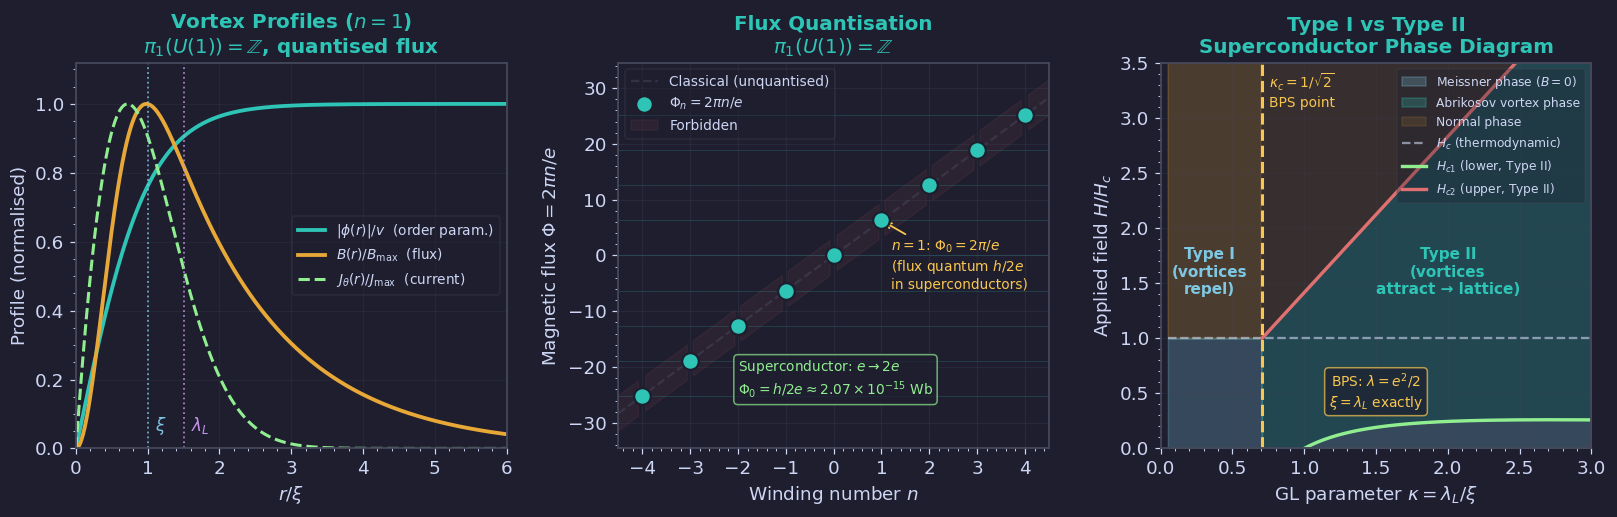

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: vortex radial profiles ──────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

r   = np.linspace(0, 6, 500)

# Approximate analytic profiles
# |phi(r)| ~ v * tanh(r/xi) for the scalar (xi = coherence length)
# B(r) ~ B0 * K0(r/lambda) near BPS; approximate with Gaussian
xi_v   = 1.0    # coherence length
lam_L  = 1.5    # London penetration depth (Type II: lambda > xi/sqrt(2))
v_val  = 1.0

# Scalar profile: phi(r) -> v as r -> inf, phi(0) = 0 (vortex core)
phi_r = v_val * np.tanh(r / xi_v)

# Magnetic field: concentrated in core, falls off on scale lambda_L
# Approximate: B(r) ~ exp(-r/lambda_L) * (1 - exp(-r^2))
B_r = np.exp(-r / lam_L) * (1 - np.exp(-2*r**2))
B_r /= B_r.max()   # normalise

# Supercurrent J ~ r * d(phi)/dr * ... approximate
J_r = r * np.exp(-r**2 / (2*xi_v**2)) * np.exp(-r / lam_L)
J_r /= J_r.max()

ax.plot(r, phi_r, color=TEAL,   lw=2.5, label=r'$|\phi(r)|/v$  (order param.)')
ax.plot(r, B_r,   color=ORANGE, lw=2.5, label=r'$B(r)/B_{\rm max}$  (flux)')
ax.plot(r, J_r,   color=GREEN,  lw=2.0, ls='--', label=r'$J_\theta(r)/J_{\rm max}$  (current)')

# Core radius and London depth
ax.axvline(xi_v,  color=BLUE,   lw=1.2, ls=':', alpha=0.8)
ax.axvline(lam_L, color=PURPLE, lw=1.2, ls=':', alpha=0.8)
ax.text(xi_v  + 0.1, 0.05, r'$\xi$',      color=BLUE,   fontsize=11)
ax.text(lam_L + 0.1, 0.05, r'$\lambda_L$', color=PURPLE, fontsize=11)

ax.set_xlabel(r'$r/\xi$')
ax.set_ylabel('Profile (normalised)')
ax.set_title(r'Vortex Profiles ($n=1$)' + '\n'
             + r'$\pi_1(U(1))=\mathbb{Z}$, quantised flux', color=TEAL)
ax.set_xlim(0, 6)
ax.set_ylim(0, 1.12)
ax.legend(fontsize=9, labelcolor=FG)
ax.grid(True, alpha=0.2)

# ── Middle: flux quantisation ─────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

n_vals   = np.arange(-4, 5)
# Flux in units of 2pi/e (set e=1)
Phi_n    = 2 * np.pi * n_vals

# Continuous reference
n_cont   = np.linspace(-4.5, 4.5, 300)
Phi_cont = 2 * np.pi * n_cont

ax2.plot(n_cont, Phi_cont, color=EDGE, lw=1.5, ls='--', alpha=0.5,
         label='Classical (unquantised)')
ax2.scatter(n_vals, Phi_n, s=120, color=TEAL, zorder=5,
            edgecolors=BG, lw=1.5, label=r'$\Phi_n = 2\pi n/e$')

# Vertical lines at each allowed flux
for n, Phi in zip(n_vals, Phi_n):
    ax2.axhline(Phi, color=TEAL, lw=0.5, alpha=0.25)

# Forbidden band shading
ax2.fill_between(n_cont, Phi_cont - np.pi, Phi_cont + np.pi,
                 where=np.abs(n_cont - np.round(n_cont)) > 0.05,
                 color=RED, alpha=0.07, label='Forbidden')

# Annotate n=1
ax2.annotate(r'$n=1$: $\Phi_0 = 2\pi/e$' + '\n' + r'(flux quantum $h/2e$' +'\nin superconductors)',
             xy=(1, 2*np.pi), xytext=(1.2,-6.0),
             fontsize=9, color=YELLOW,
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2))

# Cooper pair: 2e
ax2.text(-2.0, -25,
         r'Superconductor: $e\to 2e$' + '\n' + r'$\Phi_0 = h/2e \approx 2.07\times10^{-15}$ Wb',
         color=GREEN, fontsize=9,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.7))

ax2.set_xlabel(r'Winding number $n$')
ax2.set_ylabel(r'Magnetic flux $\Phi = 2\pi n/e$')
ax2.set_title('Flux Quantisation\n' + r'$\pi_1(U(1)) = \mathbb{Z}$', color=TEAL)
ax2.set_xlim(-4.5, 4.5)
ax2.set_xticks(n_vals)
ax2.legend(fontsize=9, labelcolor=FG, loc='upper left')
ax2.grid(True, alpha=0.25)

# ── Right: Type I vs Type II phase diagram ────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

kappa = np.linspace(0.05, 3.0, 400)   # Ginzburg-Landau parameter kappa = lambda/xi
kappa_c = 1.0 / np.sqrt(2)            # critical kappa

# Upper critical field Hc2 ~ kappa * Hc  (for Type II)
Hc  = np.ones_like(kappa)             # normalised thermodynamic critical field
Hc1 = np.where(kappa >= kappa_c,
               np.log(kappa + 1e-9) / (np.sqrt(2) * kappa + 1e-9),
               Hc)                    # lower critical field
Hc2 = np.where(kappa >= kappa_c,
               np.sqrt(2) * kappa,
               Hc)                    # upper critical field

# Phase regions
ax3.fill_between(kappa, 0, np.minimum(Hc1, 1.0),
                 color=BLUE, alpha=0.25, label='Meissner phase ($B=0$)')
ax3.fill_between(kappa, np.where(kappa >= kappa_c, Hc1, 1.0),
                 np.where(kappa >= kappa_c, Hc2, 1.0),
                 color=TEAL, alpha=0.25, label='Abrikosov vortex phase')
ax3.fill_between(kappa, np.where(kappa >= kappa_c, Hc2, 1.0),
                 3.5,
                 color=ORANGE, alpha=0.12, label='Normal phase')
ax3.fill_between(kappa[kappa < kappa_c], 1.0, 3.5,
                 color=ORANGE, alpha=0.12)

# Critical field lines
ax3.plot(kappa, Hc, color=FG, lw=1.5, ls='--', alpha=0.6,
         label=r'$H_c$ (thermodynamic)')
ax3.plot(kappa[kappa >= kappa_c], Hc1[kappa >= kappa_c],
         color=GREEN, lw=2.2, label=r'$H_{c1}$ (lower, Type II)')
ax3.plot(kappa[kappa >= kappa_c], Hc2[kappa >= kappa_c],
         color=RED, lw=2.2, label=r'$H_{c2}$ (upper, Type II)')

# Critical kappa line
ax3.axvline(kappa_c, color=YELLOW, lw=2.0, ls='--')
ax3.text(kappa_c + 0.05, 3.1,
         r'$\kappa_c = 1/\sqrt{2}$' + '\nBPS point',
         color=YELLOW, fontsize=9)

# Type labels
ax3.text(0.34, 1.4, 'Type I\n(vortices\nrepel)',
         ha='center', color=BLUE, fontsize=10, fontweight='bold')
ax3.text(2.0, 1.4, 'Type II\n(vortices\nattract → lattice)',
         ha='center', color=TEAL, fontsize=10, fontweight='bold')

# QFT connection note
ax3.text(1.5, 0.38,
         r'BPS: $\lambda = e^2/2$' + '\n' + r'$\xi = \lambda_L$ exactly',
         ha='center', color=YELLOW, fontsize=9,
         bbox=dict(boxstyle='round', fc=BG, ec=YELLOW, alpha=0.7))

ax3.set_xlabel(r'GL parameter $\kappa = \lambda_L / \xi$')
ax3.set_ylabel(r'Applied field $H / H_c$')
ax3.set_title('Type I vs Type II\nSuperconductor Phase Diagram', color=TEAL)
ax3.set_xlim(0, 3.0)
ax3.set_ylim(0, 3.5)
ax3.legend(fontsize=8, labelcolor=FG, loc='upper right')
ax3.grid(True, alpha=0.2)

plt.tight_layout(pad=1.5)
save('fig03_vortex.png', fig)

---
## All figures generated

| File | Used in slide |
|------|---------------|
| `figures/ch02/fig01_potential_dw.png`   | §2.1 · Discrete Symmetry Breaking |
| `figures/ch02/fig02_higgs_mechanism.png` | §2.3 · The Higgs Mechanism |
| `figures/ch02/fig03_vortex.png`          | §2.4 · Vortices & Superconductivity |

Copy the `figures/` folder next to `sm_ch02_slides.qmd` before rendering with Quarto.

In [5]:
import zipfile
import os

# ── 1. Zip all generated figures ──────────────────────────────────────────
ZIP_NAME = 'sm_ch02_figures.zip'
OUTDIR   = 'figures/ch02'

with zipfile.ZipFile(ZIP_NAME, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTDIR)):
        if fname.endswith('.png'):
            fpath = os.path.join(OUTDIR, fname)
            zf.write(fpath, arcname=fname)
            print(f'  added: {fname}  ({os.path.getsize(fpath)//1024} KB)')

print(f'\nArchive ready: {ZIP_NAME}  ({os.path.getsize(ZIP_NAME)//1024} KB)')

# ── 2. Trigger browser download (Colab only) ──────────────────────────────
try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started — check your browser.')
except ImportError:
    # Running locally: just tell the user where the zip is
    print(f'Not running in Colab.  Zip saved at: {os.path.abspath(ZIP_NAME)}')


  added: fig01_potential_dw.png  (203 KB)
  added: fig02_higgs_mechanism.png  (297 KB)
  added: fig03_vortex.png  (304 KB)

Archive ready: sm_ch02_figures.zip  (777 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started — check your browser.
